In [3]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

In [4]:
# Import BANK DATA
df = pd.read_csv("bank.csv")
print(df.head())

   age          job  marital  education default  balance housing loan  \
0   30   unemployed  married    primary      no     1787      no   no   
1   33     services  married  secondary      no     4789     yes  yes   
2   35   management   single   tertiary      no     1350     yes   no   
3   30   management  married   tertiary      no     1476     yes  yes   
4   59  blue-collar  married  secondary      no        0     yes   no   

    contact  day month  duration  campaign  pdays  previous poutcome   y  
0  cellular   19   oct        79         1     -1         0  unknown  no  
1  cellular   11   may       220         1    339         4  failure  no  
2  cellular   16   apr       185         1    330         1  failure  no  
3   unknown    3   jun       199         4     -1         0  unknown  no  
4   unknown    5   may       226         1     -1         0  unknown  no  


In [5]:
# Display the number of rows and columns
print("Shape:", df.shape)

# Display data types of each feature
print("\nData types:")
print(df.dtypes)

# Display the first 5 observations
display(df.head())

Shape: (4521, 17)

Data types:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [6]:
# Display information of each feature
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB
None


In [7]:
# Check the number of missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check the number of duplicate observations
print("Number of duplicates:", df.duplicated().sum())

Missing values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
Number of duplicates: 0


In [8]:
# Check target distribution
print("Target distribution:")
print(df['y'].value_counts())

# Check target proportion
print("\nTarget proportion (%):")
print(df['y'].value_counts(normalize=True) * 100)

Target distribution:
y
no     4000
yes     521
Name: count, dtype: int64

Target proportion (%):
y
no     88.476001
yes    11.523999
Name: proportion, dtype: float64


In [9]:
# Setting input features X and target output y

X = df.drop(columns=["y"])

y = df["y"].map({
    "no": 0,
    "yes": 1
})

In [10]:
# Define categorical features

nominal_columns = [
    "job",
    "marital",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome"
]

ordinal_columns = [
    "education"
]

categorical_columns = nominal_columns + ordinal_columns

In [11]:
# One-Hot Encoding

X = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("X shape after One-Hot Encoding =", X.shape)
print(X.head())

X shape after One-Hot Encoding = (4521, 42)
   age  balance  day  duration  campaign  pdays  previous  job_blue-collar  \
0   30     1787   19        79         1     -1         0                0   
1   33     4789   11       220         1    339         4                0   
2   35     1350   16       185         1    330         1                0   
3   30     1476    3       199         4     -1         0                0   
4   59        0    5       226         1     -1         0                1   

   job_entrepreneur  job_housemaid  ...  month_may  month_nov  month_oct  \
0                 0              0  ...          0          0          1   
1                 0              0  ...          1          0          0   
2                 0              0  ...          0          0          0   
3                 0              0  ...          0          0          0   
4                 0              0  ...          1          0          0   

   month_sep  poutcome_other  

In [12]:
# Split data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape =", X_train.shape)
print("X_test shape =", X_test.shape)
print("y_train shape =", y_train.shape)
print("y_test shape =", y_test.shape)

X_train shape = (3616, 42)
X_test shape = (905, 42)
y_train shape = (3616,)
y_test shape = (905,)


# **DT1: Experiment1 (Criterion: GINI)**

In [13]:
# Define model
tree = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

In [14]:
# Fit model
clf = tree.fit(X_train, y_train)

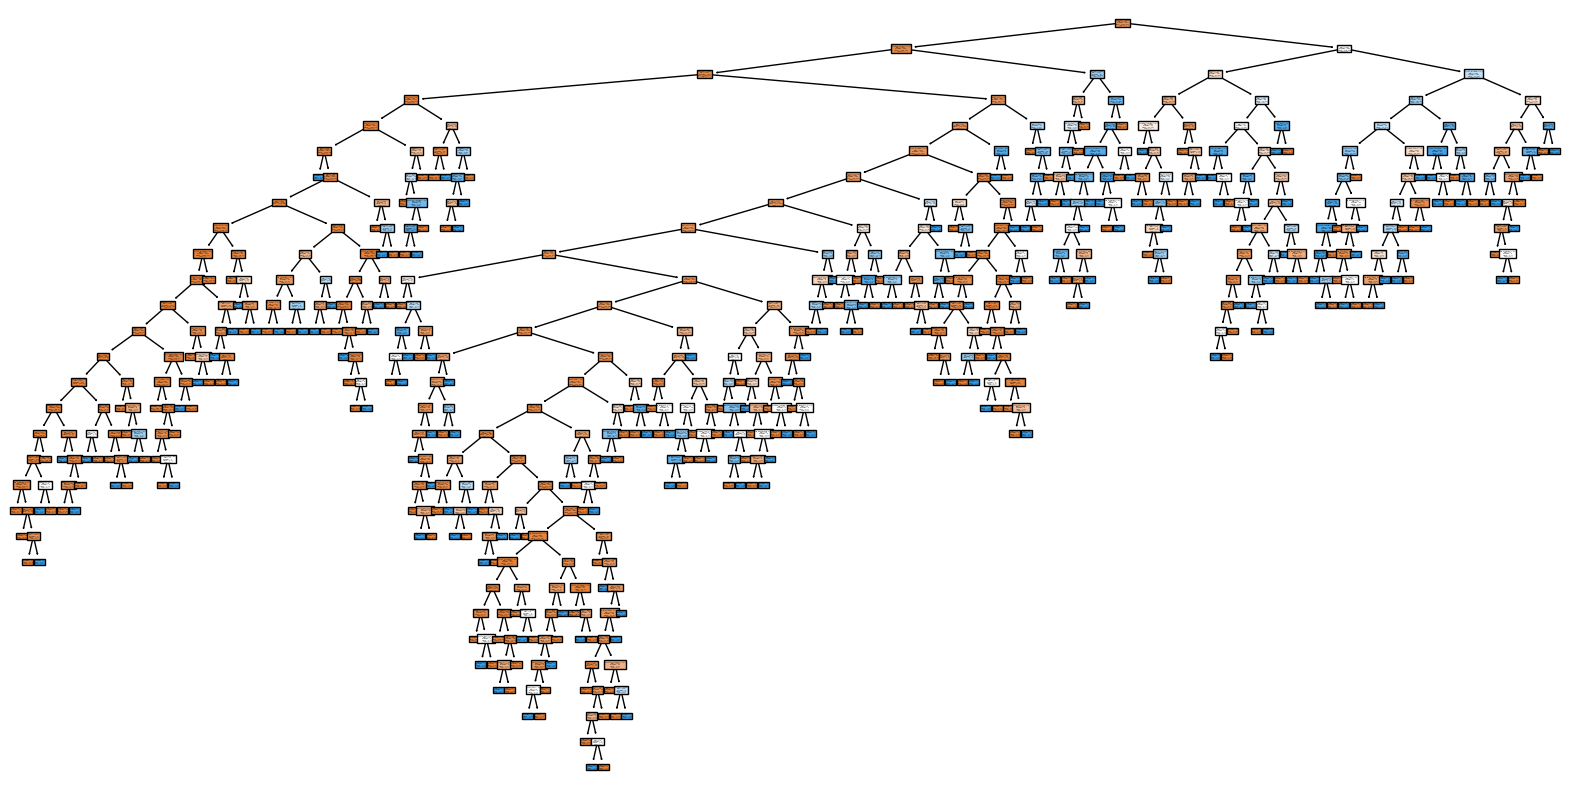

In [15]:
# Plot tree
plt.figure(figsize=(20, 10))

plot_tree(
    clf,
    feature_names=X.columns,
    class_names=["no", "yes"],
    filled=True
)

plt.show()

In [16]:
# Descriptive tree
from sklearn.tree import export_text

tree_rules = export_text(
    clf,
    feature_names=list(X.columns)
)

print(tree_rules)

|--- duration <= 645.50
|   |--- poutcome_success <= 0.50
|   |   |--- duration <= 222.50
|   |   |   |--- month_oct <= 0.50
|   |   |   |   |--- month_mar <= 0.50
|   |   |   |   |   |--- age <= 19.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- age >  19.50
|   |   |   |   |   |   |--- age <= 70.50
|   |   |   |   |   |   |   |--- pdays <= 62.50
|   |   |   |   |   |   |   |   |--- month_feb <= 0.50
|   |   |   |   |   |   |   |   |   |--- contact_unknown <= 0.50
|   |   |   |   |   |   |   |   |   |   |--- month_jun <= 0.50
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 11
|   |   |   |   |   |   |   |   |   |   |--- month_jun >  0.50
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |   |   |   |   |   |--- contact_unknown >  0.50
|   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |--- month_feb >  0.50
|   |   |   |   |   |   |   |   |   |--- balance <= 2094.

In [28]:
# Making prediction
y_pred_train_dt = clf.predict(X_train)
y_pred_test_dt = clf.predict(X_test)

# F1-score
f1_train_dt = f1_score(y_train, y_pred_train_dt, pos_label=1)
f1_test_dt = f1_score(y_test, y_pred_test_dt, pos_label=1)

print("Decision Tree")
print("Train F1-score:", f1_train_dt)
print("Test F1-score:", f1_test_dt)

Decision Tree
Train F1-score: 1.0
Test F1-score: 0.4


In [29]:
# Evaluation (F1-score, Accuracy, Recall, Precision)
f1 = f1_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred, pos_label=1)
precision = precision_score(y_test, y_pred, pos_label=1)

print("F1-score:", f1)
print("Accuracy:", accuracy)
print("Recall:", recall)
print("Precision:", precision)

F1-score: 0.4
Accuracy: 0.8541436464088398
Recall: 0.4230769230769231
Precision: 0.3793103448275862
